# Examen Práctico
**Análisis de Métodos Multivariados para la Ciencia de Datos**

Oscar Yael Baltazar Reyes - A01278421

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm

np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.precision", 4)

---
# Parte 1: Regresión simple

- Modelo verdadero: $y = 3 + 0.8X + \varepsilon,\ \varepsilon\sim N(0, 0.5^2)$
- $0.5$ es la **desviación estándar** (`scale=0.5`), no la varianza
- Fijamos una semilla para que sea reproducible

In [6]:
rng = np.random.default_rng(42)
n = 10
x = np.arange(1, 11, dtype=float)
eps = rng.normal(loc=0, scale=0.5, size=n)
y = 3 + 0.8 * x + eps

x_bar, y_bar = x.mean(), y.mean()

# Varianza muestral (ddof=1)
var_x, var_y = x.var(ddof=1), y.var(ddof=1)
r = np.corrcoef(x, y)[0, 1]

print(pd.DataFrame({"x": x, "y": y}).T)
print(f"\nx̄ = {x_bar:.4f},  s²_x = {var_x:.4f}")
print(f"ȳ = {y_bar:.4f},  s²_y = {var_y:.4f}")
print(f"r = {r:.4f}")

        0     1       2       3       4       5       6       7        8  \
x  1.0000  2.00  3.0000  4.0000  5.0000  6.0000  7.0000  8.0000   9.0000   
y  3.9524  4.08  5.7752  6.6703  6.0245  7.1489  8.6639  9.2419  10.1916   

         9  
x  10.0000  
y  10.5735  

x̄ = 5.5000,  s²_x = 9.1667
ȳ = 7.2322,  s²_y = 5.6232
r = 0.9813


## MCO por fórmulas
$S_{xy}/S_{xx}$ es "cuánto covarían x e y" dividido entre "cuánto varía x"

La recta siempre pasa por $(\bar x, \bar y)$, por eso $\hat\beta_0 = \bar y - \hat\beta_1 \bar x$

In [7]:
Sxx = np.sum((x - x_bar) ** 2)
Sxy = np.sum((x - x_bar) * (y - y_bar))
b1 = Sxy / Sxx
b0 = y_bar - b1 * x_bar

print(f"Sxx = {Sxx:.4f}")
print(f"Sxy = {Sxy:.4f}")
print(f"β̂1 = {b1:.4f}")
print(f"β̂0 = {b0:.4f}")
print(f"\nModelo estimado:  ŷ = {b0:.4f} + {b1:.4f}·x")

Sxx = 82.5000
Sxy = 63.4049
β̂1 = 0.7685
β̂0 = 3.0052

Modelo estimado:  ŷ = 3.0052 + 0.7685·x


## Solución matricial
$\hat\beta = (X^TX)^{-1}X^Ty$

La columna de unos es la que "genera" el intercepto, con una sola $x$: $X^TX = \begin{pmatrix} n & \sum x \\ \sum x & \sum x^2\end{pmatrix}$

In [10]:
X_design = np.column_stack([np.ones(n), x])
XtX = X_design.T @ X_design
XtX_inv = np.linalg.inv(XtX)
Xty = X_design.T @ y
beta_hat = XtX_inv @ Xty

print("XᵀX =\n", XtX)
print("\n(XᵀX)⁻¹ =\n", XtX_inv)
print("\nXᵀy =", Xty)
print("\nβ̂ (matricial) =", beta_hat)
print("β̂ (fórmulas)  =", np.array([b0, b1]))
print("¿Coinciden?", np.allclose(beta_hat, [b0, b1]))

XᵀX =
 [[ 10.  55.]
 [ 55. 385.]]

(XᵀX)⁻¹ =
 [[ 0.4667 -0.0667]
 [-0.0667  0.0121]]

Xᵀy = [ 72.3221 461.1767]

β̂ (matricial) = [3.0052 0.7685]
β̂ (fórmulas)  = [3.0052 0.7685]
¿Coinciden? True


## Sumas de cuadrados y ANOVA
- **SST**: variabilidad total de y alrededor de su media
- **SSR**: la parte que explica la recta
- **SSE**: lo que sobra (residuos)

$SST = SSR + SSE$ se cumple **porque el modelo tiene intercepto** (los residuos suman 0 y son ortogonales a $\hat y$)

$F = MSR/MSE$: compara la varianza explicada por grado de libertad contra la varianza del ruido

In [16]:
y_hat = X_design @ beta_hat
e = y - y_hat

SST = np.sum((y - y_bar) ** 2)
SSR = np.sum((y_hat - y_bar) ** 2)
SSE = np.sum(e ** 2)
print(f"SST = {SST:.4f},  SSR + SSE = {SSR + SSE:.4f}  ->  ¿iguales? {np.isclose(SST, SSR + SSE)}")

df_reg, df_err = 1, n - 2
MSR, MSE = SSR / df_reg, SSE / df_err
F = MSR / MSE
pF = stats.f.sf(F, df_reg, df_err)
R2 = SSR / SST

anova1 = pd.DataFrame({
    "SS": [SSR, SSE, SST],
    "df": [df_reg, df_err, n - 1],
    "MS": [MSR, MSE, np.nan],
    "F": [F, np.nan, np.nan],
    "p-valor": [pF, np.nan, np.nan],
}, index=["Regresión", "Error", "Total"])
print(anova1)
print(f"\nR² = {R2:.4f}   (check: r² = {r**2:.4f})")

SST = 50.6085,  SSR + SSE = 50.6085  ->  ¿iguales? True
                SS  df       MS         F     p-valor
Regresión  48.7295   1  48.7295  207.4648  5.2755e-07
Error       1.8790   8   0.2349       NaN         NaN
Total      50.6085   9      NaN       NaN         NaN

R² = 0.9629   (check: r² = 0.9629)


## Errores estándar, IC 95% y pruebas t
$\hat\sigma^2 = MSE$

Los SE salen de la diagonal de $MSE\,(X^TX)^{-1}$
- IC: $\hat\beta_j \pm t_{0.975,\,n-2}\, SE(\hat\beta_j)$
- Prueba: $H_0:\beta_j=0$, $t = \hat\beta_j/SE(\hat\beta_j)$ con $n-2$ gl

**Por qué $t$ y no $z$:** porque estimamos $\sigma^2$ con MSE, y eso agrega incertidumbre

In [17]:
SE_b1 = np.sqrt(MSE / Sxx)
SE_b0 = np.sqrt(MSE * (1 / n + x_bar ** 2 / Sxx))

SE_mat = np.sqrt(MSE * np.diag(XtX_inv))
print("SE fórmulas  :", np.array([SE_b0, SE_b1]))
print("SE matricial :", SE_mat)

t_crit = stats.t.ppf(0.975, df_err)
coefs = np.array([b0, b1]); SEs = np.array([SE_b0, SE_b1])
t_vals = coefs / SEs
p_vals = 2 * stats.t.sf(np.abs(t_vals), df_err)

tabla1 = pd.DataFrame({
    "β̂": coefs, "SE": SEs, "t": t_vals, "p-valor": p_vals,
    "IC95 inf": coefs - t_crit * SEs, "IC95 sup": coefs + t_crit * SEs,
}, index=["β0", "β1"])
print(f"\nt crítico (0.975, {df_err} gl) = {t_crit:.4f}\n")
print(tabla1)
print("\n¿El IC de β1 contiene el valor verdadero 0.8?",
      tabla1.loc["β1", "IC95 inf"] <= 0.8 <= tabla1.loc["β1", "IC95 sup"])

SE fórmulas  : [0.3311 0.0534]
SE matricial : [0.3311 0.0534]

t crítico (0.975, 8 gl) = 2.3060

        β̂      SE        t     p-valor  IC95 inf  IC95 sup
β0  3.0052  0.3311   9.0771  1.7403e-05    2.2418    3.7687
β1  0.7685  0.0534  14.4036  5.2755e-07    0.6455    0.8916

¿El IC de β1 contiene el valor verdadero 0.8? True


## F = t² y diagnóstico
**Por qué F = t²:** con un solo predictor, la prueba F global y la t de $\beta_1$ prueban la **misma** hipótesis ($\beta_1=0$), y una $F_{1,\nu}$ es el cuadrado de una $t_\nu$

**Cook:** mezcla qué tan grande es el residuo ($e_i^2$) con qué tanto "jala" el punto ($h_{ii}$). Aquí $p=2$ (número de parámetros, incluyendo intercepto)
Leverage en simple: $h_{ii} = \frac1n + \frac{(x_i-\bar x)^2}{S_{xx}}$
Regla común: $D_i > 1$ (o la más estricta $4/n$) → punto influyente

In [13]:
print(f"F calc = {F:.4f},  t(β1)² = {t_vals[1]**2:.4f}  ->  ¿iguales? {np.isclose(F, t_vals[1]**2)}")

H1 = X_design @ XtX_inv @ X_design.T
h = np.diag(H1)
h_formula = 1 / n + (x - x_bar) ** 2 / Sxx
p1 = 2
D = (e ** 2 / (p1 * MSE)) * (h / (1 - h) ** 2)

diag1 = pd.DataFrame({"x": x, "y": y, "ŷ": y_hat, "e": e, "h_ii": h, "Cook D": D})
print("\n¿h_ii matricial = fórmula?", np.allclose(h, h_formula))
print(diag1)
print(f"\nPuntos con D>1: {np.where(D > 1)[0].tolist()} | con D>4/n={4/n:.2f}: {np.where(D > 4/n)[0].tolist()}")

F calc = 207.4648,  t(β1)² = 207.4648  ->  ¿iguales? True

¿h_ii matricial = fórmula? True
      x        y        ŷ       e    h_ii  Cook D
0   1.0   3.9524   3.7738  0.1786  0.3455  0.0547
1   2.0   4.0800   4.5423 -0.4623  0.2485  0.2002
2   3.0   5.7752   5.3109  0.4644  0.1758  0.1188
3   4.0   6.6703   6.0794  0.5909  0.1273  0.1242
4   5.0   6.0245   6.8479 -0.8235  0.1030  0.1848
5   6.0   7.1489   7.6165 -0.4676  0.1030  0.0596
6   7.0   8.6639   8.3850  0.2789  0.1273  0.0277
7   8.0   9.2419   9.1536  0.0883  0.1758  0.0043
8   9.0  10.1916   9.9221  0.2695  0.2485  0.0680
9  10.0  10.5735  10.6907 -0.1172  0.3455  0.0236

Puntos con D>1: [] | con D>4/n=0.40: []


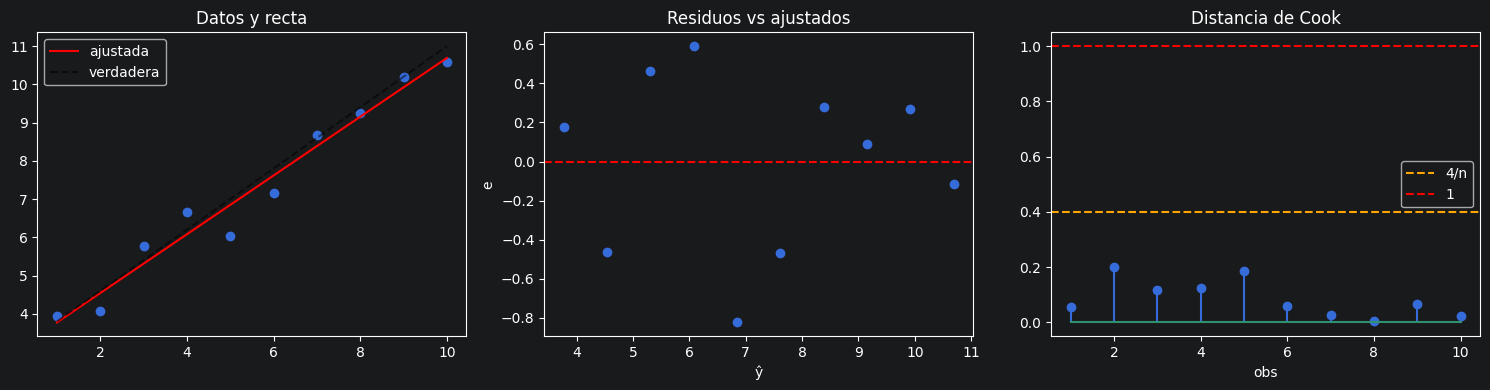

In [18]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].scatter(x, y); ax[0].plot(x, y_hat, "r-", label="ajustada"); ax[0].plot(x, 3 + 0.8*x, "k--", alpha=.5, label="verdadera")
ax[0].set_title("Datos y recta"); ax[0].legend()
ax[1].scatter(y_hat, e); ax[1].axhline(0, color="r", ls="--")
ax[1].set_xlabel("ŷ"); ax[1].set_ylabel("e"); ax[1].set_title("Residuos vs ajustados")
ax[2].stem(np.arange(1, n+1), D); ax[2].axhline(4/n, color="orange", ls="--", label="4/n"); ax[2].axhline(1, color="r", ls="--", label="1")
ax[2].set_title("Distancia de Cook"); ax[2].set_xlabel("obs"); ax[2].legend()
plt.tight_layout(); plt.show()

Con $n=10$ casi no hay poder para ver nada, se buscaría una **forma de embudo** para verificar heterocedasticidad y una **curva (U)** para verificar la falta deun término lineal

In [19]:
# Verificación con statsmodels
m1 = sm.OLS(y, X_design).fit()
print(m1.summary())
print("\nCook statsmodels == manual:", np.allclose(m1.get_influence().cooks_distance[0], D))

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.963
Model:                            OLS   Adj. R-squared:                  0.958
Method:                 Least Squares   F-statistic:                     207.5
Date:                Fri, 20 Nov 2026   Prob (F-statistic):           5.28e-07
Time:                        19:30:17   Log-Likelihood:                -5.8303
No. Observations:                  10   AIC:                             15.66
Df Residuals:                       8   BIC:                             16.27
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          3.0052      0.331      9.077      0.0

---
# Parte 2: Regresión múltiple y multicolinealidad con `wine`
Respuesta: `flavanoids`. Predictores: `total_phenols`, `od280/od315_of_diluted_wines`, `proline`.

In [20]:
from sklearn.datasets import load_wine
data = load_wine()
Xw = pd.DataFrame(data.data, columns=data.feature_names)

preds = ["total_phenols", "od280/od315_of_diluted_wines", "proline"]
resp = "flavanoids"
yw = Xw[resp].values
nw = len(Xw)
print("n =", nw)
Xw[preds + [resp]].describe().T

n = 178


,count,mean,std,min,25%,50%,75%,max
total_phenols,178.0,2.2951,0.6259,0.98,1.7425,2.355,2.800,3.88
od280/od315_of_diluted_wines,178.0,2.6117,0.7100,1.27,1.9375,2.780,3.170,4.00
proline,178.0,746.8933,314.9075,278.00,500.5000,673.500,985.000,1680.00
flavanoids,178.0,2.0293,0.9989,0.34,1.2050,2.135,2.875,5.08


## Exploración
Antes de ajustar, la correlación entre predictores ya avisa si habrá multicolinealidad (aunque el VIF es la medida correcta, porque la correlación solo ve pares)

                              total_phenols  od280/od315_of_diluted_wines  \
total_phenols                         1.000                         0.700   
od280/od315_of_diluted_wines          0.700                         1.000   
proline                               0.498                         0.313   
flavanoids                            0.865                         0.787   

                              proline  flavanoids  
total_phenols                   0.498       0.865  
od280/od315_of_diluted_wines    0.313       0.787  
proline                         1.000       0.494  
flavanoids                      0.494       1.000  

Par de predictores más correlacionado: ('total_phenols', 'od280/od315_of_diluted_wines')  (r = 0.700)


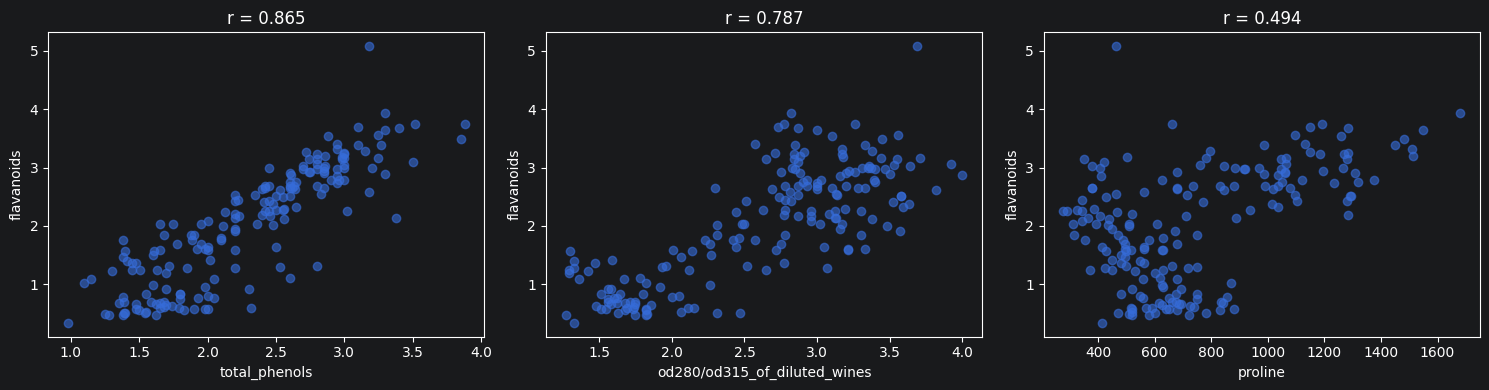

In [21]:
corr = Xw[preds + [resp]].corr()
print(corr.round(3))

cp = corr.loc[preds, preds].where(~np.eye(3, dtype=bool)).abs()
par = cp.stack().idxmax()
print(f"\nPar de predictores más correlacionado: {par}  (r = {corr.loc[par]:.3f})")

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, p in zip(ax, preds):
    a.scatter(Xw[p], yw, alpha=.6); a.set_xlabel(p); a.set_ylabel(resp)
    a.set_title(f"r = {corr.loc[p, resp]:.3f}")
plt.tight_layout(); plt.show()

## Solución matricial
Igual que en simple, solo que ahora $X$ es $n\times 4$ (unos + 3 predictores) y $MSE = SSE/(n-p-1)$

In [22]:
p = 3
Xd = np.column_stack([np.ones(nw), Xw[preds].values])   # n×4
XtX_w = Xd.T @ Xd
XtX_w_inv = np.linalg.inv(XtX_w)
beta_w = XtX_w_inv @ Xd.T @ yw

yhat_w = Xd @ beta_w
e_w = yw - yhat_w
SSE_w = e_w @ e_w
MSE_w = SSE_w / (nw - p - 1)
SE_w = np.sqrt(MSE_w * np.diag(XtX_w_inv))
t_w = beta_w / SE_w
p_w = 2 * stats.t.sf(np.abs(t_w), nw - p - 1)

names = ["const"] + preds
coef_w = pd.DataFrame({"β̂": beta_w, "SE": SE_w, "t": t_w, "p-valor": p_w}, index=names)
print(coef_w)

                                  β̂      SE        t     p-valor
const                        -1.5974  0.1339 -11.9324  2.2946e-24
total_phenols                 0.8921  0.0788  11.3192  1.3055e-22
od280/od315_of_diluted_wines  0.5122  0.0634   8.0755  1.0720e-13
proline                       0.0003  0.0001   2.7440  6.7065e-03


## ANOVA múltiple y prueba F global
$H_0: \beta_1=\beta_2=\beta_3=0$ (ningún predictor sirve) vs $H_1$: al menos uno sirve

$R^2_{adj} = 1 - \frac{SSE/(n-p-1)}{SST/(n-1)}$

In [23]:
SST_w = np.sum((yw - yw.mean()) ** 2)
SSR_w = np.sum((yhat_w - yw.mean()) ** 2)
df_r, df_e = p, nw - p - 1
MSR_w = SSR_w / df_r
F_w = MSR_w / MSE_w
pF_w = stats.f.sf(F_w, df_r, df_e)
R2_w = SSR_w / SST_w
R2adj_w = 1 - (SSE_w / df_e) / (SST_w / (nw - 1))

anova2 = pd.DataFrame({
    "SS": [SSR_w, SSE_w, SST_w], "df": [df_r, df_e, nw - 1],
    "MS": [MSR_w, MSE_w, np.nan], "F": [F_w, np.nan, np.nan], "p-valor": [pF_w, np.nan, np.nan],
}, index=["Regresión", "Error", "Total"])
print(anova2)
print(f"\nSST = SSR + SSE? {np.isclose(SST_w, SSR_w + SSE_w)}")
print(f"R² = {R2_w:.4f},  R²adj = {R2adj_w:.4f}")
print(f"F crítico (0.95; {df_r}, {df_e}) = {stats.f.ppf(.95, df_r, df_e):.4f}  ->  se rechaza H0" if pF_w < .05 else "no se rechaza H0")

                 SS   df       MS         F     p-valor
Regresión  144.8478    3  48.2826  264.6172  1.3932e-64
Error       31.7484  174   0.1825       NaN         NaN
Total      176.5962  177      NaN       NaN         NaN

SST = SSR + SSE? True
R² = 0.8202,  R²adj = 0.8171
F crítico (0.95; 3, 174) = 2.6565  ->  se rechaza H0


## Multicolinealidad (VIF)
**Intuición:** si $X_j$ se puede predecir bien con las demás ($R_j^2$ alto), entonces casi no tiene información "propia", el VIF indica **cuántas veces se infla la varianza de $\hat\beta_j$** por eso: $SE$ se infla por $\sqrt{VIF}$

Regresión auxiliar: $X_j \sim$ (las otras dos) **con intercepto**

In [24]:
def r2_ols(Xmat, yvec):
    Xm = np.column_stack([np.ones(len(yvec)), Xmat])
    b = np.linalg.solve(Xm.T @ Xm, Xm.T @ yvec)
    res = yvec - Xm @ b
    return 1 - res @ res / np.sum((yvec - yvec.mean()) ** 2)

vif_rows = []
for j in preds:
    otros = [k for k in preds if k != j]
    Rj2 = r2_ols(Xw[otros].values, Xw[j].values)
    vif_rows.append({"variable": j, "R²_j": Rj2, "VIF": 1 / (1 - Rj2)})
vif_df = pd.DataFrame(vif_rows).set_index("variable")
print(vif_df)

# Check con statsmodels
from statsmodels.stats.outliers_influence import variance_inflation_factor
print("\nVIF statsmodels:", [round(variance_inflation_factor(Xd, i), 4) for i in range(1, 4)])
print("\n¿Alguna VIF > 10?", (vif_df["VIF"] > 10).any())

                                R²_j     VIF
variable                                    
total_phenols                 0.5763  2.3603
od280/od315_of_diluted_wines  0.4916  1.9671
proline                       0.2506  1.3345

VIF statsmodels: [np.float64(2.3603), np.float64(1.9671), np.float64(1.3345)]

¿Alguna VIF > 10? False


## Leverage y Cook
$H = X(X^TX)^{-1}X^T$
- $h_{ii}$ mide qué tan lejos está $x_i$ del centro de los datos (en el espacio de predictores)
- Se cumple $\sum h_{ii} = $ número de parámetros, entonces el promedio es $(p+1)/n$; la regla "2×promedio" marca puntos altos

In [25]:
H = Xd @ XtX_w_inv @ Xd.T
h_w = np.diag(H)
print(f"traza(H) = {h_w.sum():.4f}  (= número de parámetros, {p+1})")

k = p + 1
umbral_p  = 2 * p / nw
umbral_k  = 2 * k / nw
D_w = (e_w ** 2 / (k * MSE_w)) * (h_w / (1 - h_w) ** 2)   # en Cook se usa p = # parámetros

print(f"\nObs con h_ii > 2p/n  (p=3, umbral={umbral_p:.4f}): {np.sum(h_w > umbral_p)}")
print(f"Obs con h_ii > 2(p+1)/n (umbral={umbral_k:.4f}): {np.sum(h_w > umbral_k)} -> {np.where(h_w > umbral_k)[0].tolist()}")
print(f"\nCook máximo = {D_w.max():.4f} (obs {D_w.argmax()})")
print(f"Obs con D > 1: {np.where(D_w > 1)[0].tolist()}")
print(f"Obs con D > 4/n ({4/nw:.4f}): {np.where(D_w > 4/nw)[0].tolist()}")

m2 = sm.OLS(yw, Xd).fit()
print("\n¿Cook manual = statsmodels?", np.allclose(D_w, m2.get_influence().cooks_distance[0]))

traza(H) = 4.0000  (= número de parámetros, 4)

Obs con h_ii > 2p/n  (p=3, umbral=0.0337): 25
Obs con h_ii > 2(p+1)/n (umbral=0.0449): 8 -> [3, 14, 18, 52, 63, 98, 105, 152]

Cook máximo = 0.1844 (obs 121)
Obs con D > 1: []
Obs con D > 4/n (0.0225): [3, 18, 74, 98, 121, 132, 139, 149, 150, 158, 159]

¿Cook manual = statsmodels? True


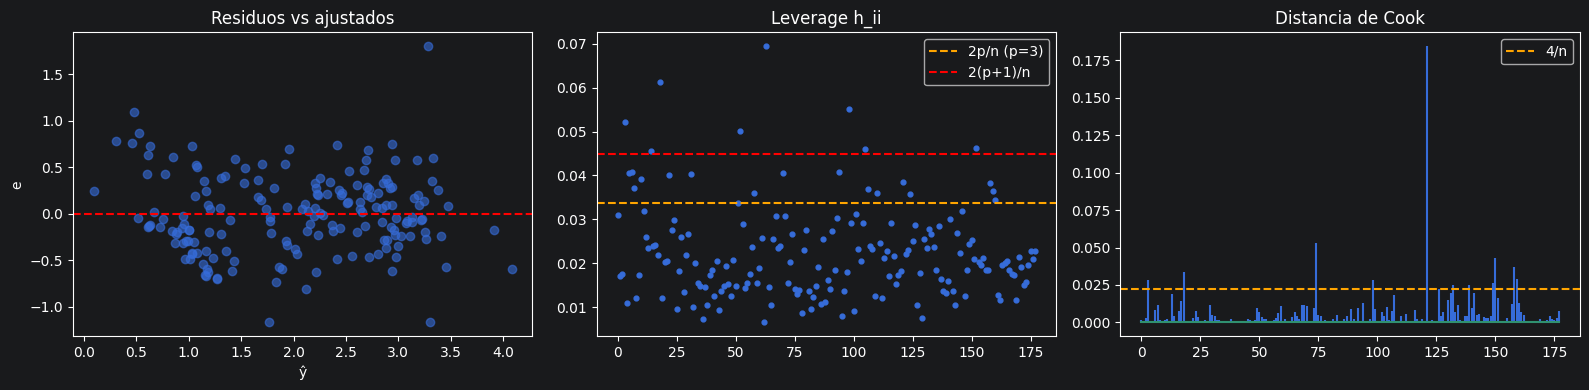

In [26]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].scatter(yhat_w, e_w, alpha=.6); ax[0].axhline(0, color="r", ls="--")
ax[0].set_title("Residuos vs ajustados"); ax[0].set_xlabel("ŷ"); ax[0].set_ylabel("e")
ax[1].scatter(range(nw), h_w, s=12); ax[1].axhline(umbral_p, color="orange", ls="--", label="2p/n (p=3)")
ax[1].axhline(umbral_k, color="r", ls="--", label="2(p+1)/n"); ax[1].set_title("Leverage h_ii"); ax[1].legend()
ax[2].stem(range(nw), D_w, markerfmt=" "); ax[2].axhline(4/nw, color="orange", ls="--", label="4/n")
ax[2].set_title("Distancia de Cook"); ax[2].legend()
plt.tight_layout(); plt.show()

**Conclusión:** hay observaciones con leverage alto, pero **ninguna es influyente según $D_i>1$** (el máximo anda en ~0.18). Leverage alto ≠ influyente: un punto lejano que cae sobre la tendencia no mueve la recta. Influencia = leverage **y** residuo grande

## Comparación de modelos (completo vs reducido)
Retiramos la variable con mayor VIF (`total_phenols`)

Log-verosimilitud gaussiana en el MLE: $\log L = -\frac n2\left[\log(2\pi) + \log\left(\frac{SSE}{n}\right) + 1\right]$

- AIC/BIC: **menor es mejor**
- BIC castiga más ($\log n > 2$ cuando $n>7$)
- $k$ = número de $\beta$'s (como `statsmodels`)
- Si cuentas también $\sigma^2$, todos suben +2 (AIC) o $+\log n$ (BIC), pero **la comparación no cambia**

In [27]:
def ajustar(cols):
    Xm = np.column_stack([np.ones(nw), Xw[cols].values])
    b = np.linalg.solve(Xm.T @ Xm, Xm.T @ yw)
    res = yw - Xm @ b
    sse = res @ res
    kk = Xm.shape[1]
    r2 = 1 - sse / SST_w
    r2a = 1 - (sse / (nw - kk)) / (SST_w / (nw - 1))
    logL = -nw / 2 * (np.log(2 * np.pi) + np.log(sse / nw) + 1)
    return dict(b=pd.Series(b, index=["const"] + cols), R2=r2, R2adj=r2a, logL=logL,
                AIC=-2 * logL + 2 * kk, BIC=-2 * logL + kk * np.log(nw), k=kk)

drop = vif_df["VIF"].idxmax()
red_cols = [c for c in preds if c != drop]
full, red = ajustar(preds), ajustar(red_cols)
print("Variable eliminada:", drop)

comp = pd.DataFrame({m: {kk: v[kk] for kk in ["k", "R2", "R2adj", "logL", "AIC", "BIC"]}
                     for m, v in [("Completo", full), ("Reducido", red)]})
print(comp)
print(f"\nCheck statsmodels completo: AIC={m2.aic:.4f}, BIC={m2.bic:.4f}")

print("\nCoeficientes:")
print(pd.DataFrame({"Completo": full["b"], "Reducido": red["b"]}))

Variable eliminada: total_phenols
       Completo  Reducido
k        4.0000    3.0000
R2       0.8202    0.6878
R2adj    0.8171    0.6843
logL   -99.1403 -148.2488
AIC    206.2806  302.4975
BIC    219.0077  312.0429

Check statsmodels completo: AIC=206.2806, BIC=219.0077

Coeficientes:
                              Completo  Reducido
const                          -1.5974   -1.1984
od280/od315_of_diluted_wines    0.5122    0.9865
proline                         0.0003    0.0009
total_phenols                   0.8921       NaN


**Resultado:** el modelo completo gana en todo ($R^2_{adj}$ más alto, AIC y BIC más bajos, y por mucho). Quitar `total_phenols` es mala idea: es el predictor más fuerte (r ≈ 0.86 con flavanoids) y su VIF ni siquiera es problemático. **Moraleja:** quitar la de mayor VIF solo tiene sentido si el VIF realmente es alto.

Fíjate que el coeficiente de `od280/od315` casi se **duplica** (≈0.51 → ≈0.99) al quitar `total_phenols`: absorbe parte del efecto de la variable eliminada (sesgo por variable omitida). No cambia de signo aquí, pero es la misma mecánica.

## Respuesta a las preguntas
**¿Qué aporta el VIF que el $R^2$ no captura?**
- El $R^2$ mide qué tan bien el modelo **completo** predice $y$, puede ser altísimo aunque los predictores sean redundantes entre ellos
- El VIF mide la **redundancia entre predictores**, y con eso qué tan **inestables/imprecisos** son los coeficientes individuales ($SE$ inflado por $\sqrt{VIF}$)
- Podemos tener $R^2$ alto + F global significativa + ninguna t individual significativa: un síntoma clásico de multicolinealidad; nos percatamos por el VIF, más no por $R^2$

**¿Qué implica que un coeficiente cambie de signo al eliminar otra variable?**
- Que el coeficiente es un efecto **parcial** ("manteniendo las demás constantes"), no marginal, quitando una variable correlacionada, la que queda absorbe su efecto (sesgo por variable omitida)
- Es síntoma de multicolinealidad y/o confusión: la interpretación individual de ese $\beta$ **no es confiable**, aunque las predicciones del modelo sí lo sean

---
# Parte 3 (EXTRA): Regresión logística con `iris`
Versicolor → 0, virginica → 1. Positivo = virginica

In [28]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, accuracy_score, roc_curve, roc_auc_score

iris = load_iris()
Xi = pd.DataFrame(iris.data, columns=iris.feature_names)
yi_raw = iris.target

mask = yi_raw != 0                         # quitamos setosa
Xi = Xi[mask].reset_index(drop=True)
yi = (yi_raw[mask] == 2).astype(int)       # versicolor=0, virginica=1
print("n =", len(yi), "| conteo:", np.bincount(yi))

X_tr, X_te, y_tr, y_te = train_test_split(Xi, yi, test_size=0.2, stratify=yi, random_state=42)

# estandarizar: se ajusta SOLO con train (si no, hay fuga de información del test)
sc = StandardScaler().fit(X_tr)
Z_tr = pd.DataFrame(sc.transform(X_tr), columns=Xi.columns)
Z_te = pd.DataFrame(sc.transform(X_te), columns=Xi.columns)
print("train:", np.bincount(y_tr), "| test:", np.bincount(y_te))

n = 100 | conteo: [50 50]
train: [40 40] | test: [10 10]


## Ajuste, SE, z, p-valores y odds ratios
Se usa `statsmodels.Logit` porque da inferencia (SE, z, p), `sklearn.LogisticRegression` **no** da p-valores y además aplica **regularización L2 por defecto** (`C=1`), terminando con coeficientes más chicos

- $OR_j = e^{\hat\beta_j}$; IC: $e^{\hat\beta_j \pm 1.96\,SE_j}$ (se exponencian los extremos del IC de $\beta$, por eso el IC del OR **no es simétrico**)
- Prueba de Wald: $z = \hat\beta_j/SE_j$ (z y no t porque es asintótico por MV)

In [29]:
logit = sm.Logit(y_tr, sm.add_constant(Z_tr)).fit(disp=0)
print(logit.summary())

ci = logit.conf_int()
or_tab = pd.DataFrame({
    "β̂": logit.params, "SE": logit.bse, "z": logit.tvalues, "p-valor": logit.pvalues,
    "OR": np.exp(logit.params), "OR IC95 inf": np.exp(ci[0]), "OR IC95 sup": np.exp(ci[1]),
})
or_tab

                           Logit Regression Results                           
Dep. Variable:                      y   No. Observations:                   80
Model:                          Logit   Df Residuals:                       75
Method:                           MLE   Df Model:                            4
Date:                Fri, 20 Nov 2026   Pseudo R-squ.:                  0.9231
Time:                        19:38:29   Log-Likelihood:                -4.2638
converged:                       True   LL-Null:                       -55.452
Covariance Type:            nonrobust   LLR p-value:                 3.068e-21
                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                 0.4477      0.948      0.472      0.637      -1.411       2.306
sepal length (cm)    -1.1384      2.244     -0.507      0.612      -5.536       3.260
sepal width (cm)     -0.

,β̂,SE,z,p-valor,OR,OR IC95 inf,OR IC95 sup
const,0.4477,0.9483,0.4721,0.6369,1.5647,0.2439,10.0374
sepal length (cm),-1.1384,2.2439,-0.5073,0.6119,0.3203,0.0039,26.0389
sepal width (cm),-0.8174,2.0913,-0.3908,0.6959,0.4416,0.0073,26.6139
petal length (cm),5.5039,4.0819,1.3484,0.1775,245.6535,0.0824,732551.5808
petal width (cm),6.5176,3.2553,2.0022,0.0453,676.9824,1.1473,399465.3175


## Interpretación de las dos variables con mayor |β̂|
Como los predictores están **estandarizados**, el OR es "por cada **desviación estándar** de aumento", manteniendo las demás constantes

In [30]:
top2 = or_tab.drop("const")["β̂"].abs().sort_values(ascending=False).index[:2]
for v in top2:
    b, orv = or_tab.loc[v, "β̂"], or_tab.loc[v, "OR"]
    print(f"{v}: β̂ = {b:.3f}, OR = {orv:.2f}")
    print(f"  -> Por cada 1 DE más de {v} (≈{sc.scale_[list(Xi.columns).index(v)]:.2f} cm), "
          f"los odds de ser virginica se multiplican por {orv:.1f}, manteniendo lo demás fijo.")
    print(f"  -> IC95% del OR: [{or_tab.loc[v,'OR IC95 inf']:.2f}, {or_tab.loc[v,'OR IC95 sup']:.2f}]"
          f"  {'(contiene 1 → no significativo al 5%)' if or_tab.loc[v,'OR IC95 inf'] < 1 < or_tab.loc[v,'OR IC95 sup'] else '(no contiene 1 → significativo)'}\n")

petal width (cm): β̂ = 6.518, OR = 676.98
  -> Por cada 1 DE más de petal width (cm) (≈0.44 cm), los odds de ser virginica se multiplican por 677.0, manteniendo lo demás fijo.
  -> IC95% del OR: [1.15, 399465.32]  (no contiene 1 → significativo)

petal length (cm): β̂ = 5.504, OR = 245.65
  -> Por cada 1 DE más de petal length (cm) (≈0.81 cm), los odds de ser virginica se multiplican por 245.7, manteniendo lo demás fijo.
  -> IC95% del OR: [0.08, 732551.58]  (contiene 1 → no significativo al 5%)



## Evaluación en prueba
- **Sensibilidad** = TP/(TP+FN): de las virginica reales, cuántas atrapé
- **Especificidad** = TN/(TN+FP): de las versicolor reales, cuántas dije bien
- **ROC:** sensibilidad vs (1 − especificidad) moviendo el umbral; **AUC** = probabilidad de que una virginica al azar reciba mayor score que una versicolor al azar

                    Pred 0  Pred 1
Real versicolor(0)       9       1
Real virginica(1)        0      10

Accuracy = 0.950 | Sensibilidad = 1.000 | Especificidad = 0.900 | AUC = 0.990


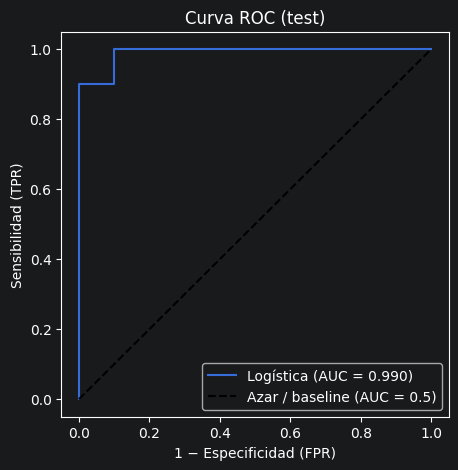

In [31]:
p_te = logit.predict(sm.add_constant(Z_te, has_constant="add"))
yhat_te = (p_te >= 0.5).astype(int)

cm = confusion_matrix(y_te, yhat_te)
tn, fp, fn, tp = cm.ravel()
acc = (tp + tn) / cm.sum()
sens = tp / (tp + fn)
spec = tn / (tn + fp)
auc = roc_auc_score(y_te, p_te)

print(pd.DataFrame(cm, index=["Real versicolor(0)", "Real virginica(1)"],
                   columns=["Pred 0", "Pred 1"]))
print(f"\nAccuracy = {acc:.3f} | Sensibilidad = {sens:.3f} | Especificidad = {spec:.3f} | AUC = {auc:.3f}")

fpr, tpr, _ = roc_curve(y_te, p_te)
plt.figure(figsize=(5, 5))
plt.plot(fpr, tpr, label=f"Logística (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Azar / baseline (AUC = 0.5)")
plt.xlabel("1 − Especificidad (FPR)"); plt.ylabel("Sensibilidad (TPR)"); plt.title("Curva ROC (test)")
plt.legend(); plt.show()

## Baseline: siempre la clase mayoritaria
**Por qué:** un modelo solo vale si le gana a "no pensar". Con 50/50 no hay mayoritaria real (en train hay empate 40/40); el baseline atina ~50% y, como da el **mismo score a todos**, su AUC = 0.5 (no puede ordenar nada)

In [32]:
from sklearn.dummy import DummyClassifier
dummy = DummyClassifier(strategy="most_frequent").fit(Z_tr, y_tr)
acc_base = accuracy_score(y_te, dummy.predict(Z_te))
auc_base = roc_auc_score(y_te, dummy.predict_proba(Z_te)[:, 1])

print(f"Baseline:  accuracy = {acc_base:.3f}, AUC = {auc_base:.3f}")
print(f"Logística: accuracy = {acc:.3f}, AUC = {auc:.3f}")
print(f"Mejora:    +{acc - acc_base:.3f} en accuracy, +{auc - auc_base:.3f} en AUC")

Baseline:  accuracy = 0.500, AUC = 0.500
Logística: accuracy = 0.950, AUC = 0.990
Mejora:    +0.450 en accuracy, +0.490 en AUC


## Preguntas (+ Hosmer-Lemeshow)
Hosmer-Lemeshow: se ordenan las observaciones por $\hat p$, se parten en $g$ grupos (deciles) y se compara observado vs esperado con $\chi^2_{g-2}$. **$H_0$: el modelo está bien calibrado** (p alto = no hay evidencia de mal ajuste)

In [33]:
def hosmer_lemeshow(y, p, g=10):
    df_ = pd.DataFrame({"y": np.asarray(y), "p": np.asarray(p)})
    df_["grupo"] = pd.qcut(df_["p"].rank(method="first"), g, labels=False)
    t = df_.groupby("grupo").agg(obs=("y", "sum"), esp=("p", "sum"), n=("y", "size"))
    num = (t["obs"] - t["esp"]) ** 2
    den = t["esp"] * (1 - t["esp"] / t["n"])
    HL = np.sum(num / den.clip(lower=1e-10))
    return HL, stats.chi2.sf(HL, g - 2), t

p_tr = logit.predict(sm.add_constant(Z_tr))
HL, pHL, tabla_hl = hosmer_lemeshow(y_tr, p_tr, g=10)
print(tabla_hl.round(3))
print(f"\nHL = {HL:.3f}, gl = 8, p-valor = {pHL:.3f}")
print("Ojo: varios grupos tienen esperados ~0 o ~n (probabilidades casi 0/1), así que el χ² es poco confiable aquí.")

       obs    esp  n
grupo               
0        0  0.000  8
1        0  0.000  8
2        0  0.002  8
3        0  0.021  8
4        1  0.818  8
5        7  7.182  8
6        8  7.978  8
7        8  7.999  8
8        8  8.000  8
9        8  8.000  8

HL = 0.136, gl = 8, p-valor = 1.000
Ojo: varios grupos tienen esperados ~0 o ~n (probabilidades casi 0/1), así que el χ² es poco confiable aquí.


**¿Qué variables son significativas?**
Al 5%, prácticamente solo `petal width` (y depende del split); el resto tiene p > 0.05. La razón es la casi-separación + la correlación entre las medidas de pétalo, que inflan los SE; los pétalos son los que discriminan (|β| más grandes, mismo signo positivo: más grande → más virginica), sépalos aportan poco

**¿El modelo clasifica bien?**
Sí: con accuracy ~0.95 y AUC ~0.99 en prueba, muy por arriba del baseline (0.5 / 0.5), teniendo solo 20 obs de prueba, 1 error = 5 puntos de accuracy, así que la estimación es ruidosa (como extra, una validación cruzada sería más sólida)

**Limitaciones de usar Hosmer-Lemeshow como único criterio:**
- Mide **calibración** (que $\hat p$ coincida con frecuencias), **no discriminación**: un modelo puede pasar HL y separar fatal, o al revés
- Depende de cuántos grupos $g$ elijas (cambia $g$ y puede cambiar la conclusión)
- Bajo poder con $n$ chico (aquí n=80): "no rechazar" ≠ "buen modelo"; con $n$ enorme rechaza por diferencias triviales
- Con probabilidades pegadas a 0/1 (separación), los esperados por grupo son ~0 y la aproximación $\chi^2$ falla
- Por eso se complementa con AUC/ROC, matriz de confusión, devianza/AIC

**¿Por qué el AUC es más informativo que la accuracy con desbalance?**
- La accuracy depende del umbral y de la proporción de clases: con 90/10, el clasificador trivial ya tiene 90% sin aprender nada
- El AUC evalúa la **capacidad de ordenar** positivos sobre negativos en todos los umbrales; el baseline constante siempre da AUC = 0.5 sin importar el desbalance

**¿Y si fuera setosa vs el resto?**
- Desbalance 50/100 (1/3 vs 2/3): el baseline "siempre no-setosa" ya tiene **66.7%** de accuracy, así que la accuracy se infla y engaña; el AUC no
- Además, setosa es **linealmente separable** de las otras dos (pétalos mucho más chicos) → **separación completa**: el MLE no existe (los β divergen), statsmodels tira error/warning, SE infinitos. La clasificación sería perfecta (AUC = 1), pero la inferencia (p-valores, IC de OR) no tendría sentido

In [1]:
!jupyter nbconvert --to html "Examen_Práctico.ipynb"

[NbConvertApp] Converting notebook Examen_Práctico.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 4 image(s).
[NbConvertApp] Writing 703000 bytes to Examen_Práctico.html
